# 09-数字图像与OpenCV入门


## 1. 本篇范围与学习目标

前面的运动学与控制笔记讨论了机械臂如何运动。这一篇开始学习视觉：先理解计算机怎样存储图像，再用 OpenCV 操作图像数据。

本篇依据课程 `opencv.pptx`，原课标题为“数字图像基础与OpenCV入门”，覆盖第 **1—9 页及第 11 页**。课程目标是建立数字图像的底层认知，掌握 OpenCV 的核心数据结构与基本操作。

内容依次包括计算机视觉任务、像素与矩阵、OpenCV、BGR 通道、环境安装、NumPy 红线示例、摄像头与 ROI 案例，以及图像坐标系。第 10 页的颜色识别和后面的目标跟踪，按课程规划放在下一篇。

摄像头预览与 ROI 选择两页只描述案例功能，没有附实现代码。本篇保留这些功能目标；已有代码按 PPT 整理，必要的索引说明在对应位置标注。


## 2. 什么是计算机视觉

计算机视觉（Computer Vision，简称 CV）研究如何让机器从数字图像和视频中获取信息、进行处理，并据此做出决策。

“看见图像”与“理解图像”是不同层次的能力。读取一张图片得到的是像素数据；判断其中有什么、在哪里、在做什么，需要进一步处理。

课件列出四类核心任务：

| 任务 | 英文 | 要回答的问题 | 课件示例 |
|---|---|---|---|
| 图像分类 | Classification | 这张图里有什么？ | 判断图片是猫还是狗 |
| 目标检测 | Detection | 目标在什么位置？ | 找到猫在图中的位置 |
| 图像分割 | Segmentation | 哪些像素属于目标？ | 区分属于猫的像素 |
| 行为识别 | Action Recognition | 视频中的对象在做什么？ | 判断人在执行什么动作 |

课件中的应用包括自动驾驶的障碍物识别、医疗影像的病灶检测、工业产品质检与机器人分拣、安防中的人脸识别与人流统计，以及增强现实中的 AR 滤镜。

对于机械臂，视觉可以提供待抓取物体的信息；本篇先解决图像数据怎样表达与访问的问题。


## 3. 像素：图像的基本单位

我们看到的图像通常是连续、平滑的。数字图像把它表示为一个规则网格，每个位置记录一种颜色或亮度。这个基本单位称为**像素（Pixel）**。

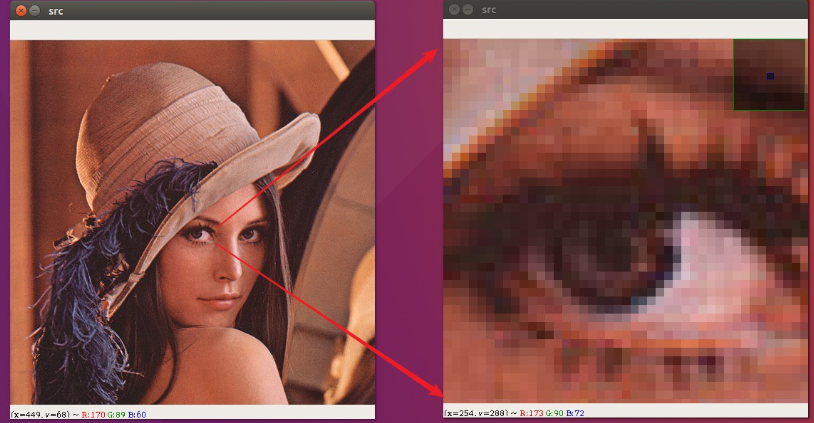

原图展示了整体图像和眼部局部的放大效果。放大后能够看到像素网格，帮助理解计算机处理的对象是一个个离散位置上的数值。

课件进一步给出“图像 = 矩阵”的理解方式：将像素按行、列排列，把每个位置的亮度或颜色存入数组。后续修改某个像素，就是修改数组中对应的数值。


## 4. 灰度图与彩色图怎样存储

### 4.1 灰度图：每个位置一个亮度值

灰度图可以用二维矩阵表示。每个元素对应一个像素，元素值表示亮度。

课件采用的范围是 `0—255`：`0` 表示黑，`255` 表示白，中间的值表示不同亮度的灰色。

### 4.2 彩色图：每个位置三个通道值

课件用 B、G、R 三个通道描述彩色图像，分别记录蓝、绿、红的强度。可以把它理解为三个同样大小的二维矩阵，也可以理解为每个像素存有三个数值的三维数组。

| 图像形式 | 常见数组形状 | 每个像素记录的内容 |
|---|---|---|
| 灰度图 | `(H, W)` | 一个亮度值 |
| 三通道彩色图 | `(H, W, 3)` | 三个颜色通道值 |

这里 `H` 是高度，对应行数；`W` 是宽度，对应列数；最后一维 `3` 是通道数。

> **补充说明：**这里的 `0—255` 对应本课使用的无符号 8 位图像，不是所有图像数据类型的统一范围。“三维数组”中的三个维度是高、宽、通道，不是物体在空间中的三维坐标。


## 5. 为什么使用 OpenCV

OpenCV 的全称是 **Open Source Computer Vision Library**，即开源计算机视觉库。

课件选择它作为入门工具，主要因为它把常见视觉操作封装成可调用的功能，便于从图像数据进入实际处理。

| 特点 | 对学习与实践的作用 |
|---|---|
| 开源 | 可以查阅实现、示例与相关资料 |
| 算法与功能丰富 | 支持图像读写、滤波、目标检测、特征匹配等操作 |
| 跨平台 | 可用于 Windows、Linux、macOS、Android、iOS 等平台 |
| 多语言接口 | 可在不同语言中使用，本课程重点使用 Python |
| 与 Python 数据生态配合 | 可以结合 NumPy、SciPy、Matplotlib 进行数据处理与快速原型开发 |
| 社区活跃 | 有较多文档、示例和问题讨论可供参考 |

在本课的 Python 示例中，图像以 NumPy 数组表示。NumPy 负责创建和修改数组，OpenCV 负责图像相关操作及窗口显示，两者共同构成后续案例的基础。


## 6. 颜色顺序：OpenCV 常用 BGR

网页等场景常使用 RGB 顺序，即红（Red）、绿（Green）、蓝（Blue）。OpenCV 的常规三通道彩色读取与显示使用 **BGR** 顺序：蓝、绿、红。

因此，读取或设置像素值时，必须先确认当前图像的通道格式。

| 颜色 | RGB 表示 | BGR 表示 |
|---|---|---|
| 红色 | `(255, 0, 0)` | `(0, 0, 255)` |
| 绿色 | `(0, 255, 0)` | `(0, 255, 0)` |
| 蓝色 | `(0, 0, 255)` | `(255, 0, 0)` |

> 在本课的 BGR 数组中，`(0, 0, 255)` 是红色。把 RGB 数值直接当作 BGR 使用，容易把红色与蓝色弄反。

**补充说明：**PPT 用早期相机硬件的历史原因解释 BGR。操作时应把它理解为 OpenCV 常用接口的约定，不能从中推断所有相机排列都采用 BGR。灰度图，以及已转换成 RGB、HSV 等格式的图像，应按各自格式理解通道。


## 7. 安装 OpenCV 并验证

### 7.1 在项目使用的 Python 环境中安装

在目标项目的终端中，确认已进入准备运行课程示例的 Python 环境，再执行课件命令：

```powershell
pip install opencv-python
```

如果需要使用课件提供的镜像地址，可以改用以下命令，两种方式选择一种即可：

```powershell
pip install opencv-python -i https://mirrors.aliyun.com/pypi/simple/
```

安装时的包名是 `opencv-python`，在 Python 中的导入名是 `cv2`。

### 7.2 在同一环境中验证导入

按课件步骤，在该环境的终端输入：

```powershell
python
```

进入 Python 解释器后，执行：

```python
import cv2
print(f"OpenCV Version: {cv2.__version__}")
```

如果导入没有报错，且成功打印出 OpenCV 的版本号，说明当前解释器能够使用这个库。若出现 `ModuleNotFoundError`，首先核对安装和运行是否使用同一个 Python 环境。

**补充说明：**版本打印验证的是库的导入；摄像头是否能打开、图像窗口是否能显示，还要通过对应案例检查。


## 8. 课件示例：用 NumPy 创建一条红线

课件第 7 页强调：在 Python 中，OpenCV 图像就是 NumPy 数组。下面先构造一张黑色图像，再把指定行的像素修改成红色，最后用 OpenCV 显示。

这是一段 Python 脚本示例；运行时使用已安装 OpenCV 的环境。代码保留了课件的变量、参数、循环与注释，仅整理排版：

```python
import cv2 as cv
import numpy as np

# 构建一个空白的矩阵
img = np.zeros((30, 40, 3), np.uint8)

# 将第15行所有像素点全都改成红色
for i in range(40):
    # 设置第15行颜色为红色
    img[15, i] = (0, 0, 255)

# 显示图片
cv.imshow("src", img)
cv.waitKey(0)
cv.destroyAllWindows()
```

预期显示的是一张宽 `40` 像素、高 `30` 像素的黑色图像，其中一整行是红色。图像本身只有 `40 × 30` 像素，显示区域较小是正常现象。

> **课件索引说明：**原注释写“第15行”，代码使用的是行索引 `15`。Python 数组从 `0` 开始计数，所以实际红线位于从上往下第 **16 行**。本篇保留原代码，并明确区分自然语言的行号与数组索引。


## 9. 理解红线示例的数组与显示操作

### 9.1 创建图像

`np.zeros((30, 40, 3), np.uint8)` 创建一个形状为 `(30, 40, 3)` 的数组：

- `30` 是高度，即有 30 行。
- `40` 是宽度，即每行有 40 列。
- `3` 是通道数，按本例的 BGR 顺序解释。
- `np.uint8` 是无符号 8 位整数类型，可以表示 `0—255`。

`zeros` 把所有数值初始化为 `0`，每个像素都是 `(0, 0, 0)`，因此初始图像是黑色。

### 9.2 修改指定行

`range(40)` 依次产生 `0—39` 的列索引。循环中的 `img[15, i]` 固定行索引为 `15`，列索引随 `i` 变化，因此遍历了这一行的全部 40 个像素。

每个像素被赋值为 BGR 的 `(0, 0, 255)`：蓝与绿的强度为 `0`，红的强度为 `255`。其余行没有被修改，仍然保持黑色。

这里再次体现数组的访问顺序：**先行，后列**。`img[15, i]` 的第一个索引表示纵向位置，第二个索引表示横向位置。

### 9.3 显示并关闭窗口

| 代码 | 作用 |
|---|---|
| `import cv2 as cv` | 将 `cv2` 导入并起别名 `cv`，后续通过 `cv` 调用 |
| `cv.imshow("src", img)` | 在名为 `src` 的窗口中显示图像 |
| `cv.waitKey(0)` | 等待按键，并让窗口处理显示与输入事件 |
| `cv.destroyAllWindows()` | 关闭 OpenCV 创建的窗口 |

`waitKey(0)` 中的 `0` 表示持续等待按键。程序先显示图像，等待用户按键后，才继续执行关闭窗口的语句。


## 10. 案例一：赋予机器“眼睛”

课件第 8 页的功能目标是：连接并打开电脑摄像头，在一个窗口中实时显示捕捉到的画面。

与前面创建一张静态图像相比，这个案例的输入变成了摄像头连续提供的图像帧。随着新帧到来，窗口中的画面也持续更新。

这里首先获得实时视觉输入。后续的选择区域、识别物体等功能，才能在这个输入上继续处理。该页没有提供摄像头读取循环、设备参数或窗口退出代码。


## 11. 案例二：选择 ROI 区域

ROI 是 **Region of Interest**，即感兴趣区域。它表示当前希望重点处理的图像局部。

课件第 9 页提出的功能是：在实时视频流中，允许用户用鼠标拖拽画出矩形框，再裁剪出框内的 ROI 区域。

选取 ROI 后，处理对象可以从整幅画面缩小到选中的局部。它与目标检测中的“找到目标位置”有关联，但在这个案例中，区域由用户手动选择。

**补充索引说明：**如果一个有效矩形用左上角 `(x, y)`、宽度 `w`、高度 `h` 表示，对应的数组区域可写成 `img[y:y+h, x:x+w]`。切片的结束位置不包含在结果中，因此这里取的是从 `y` 开始的 `h` 行、从 `x` 开始的 `w` 列；前提是矩形完整位于图像范围内。

这只是帮助理解裁剪与数组的联系。PPT 没有附鼠标交互或实时裁剪程序。


## 12. 图像坐标系：左上角为原点

课件第 11 页给出图像坐标系的约定：

- 原点 `(0, 0)` 位于图像左上角。
- `x` 从左向右增加。
- `y` 从上向下增加。

这与通常在数学课中使用的“横轴向右、纵轴向上”的笛卡尔坐标系不同。

| 表达方式 | 顺序 | 对应含义 |
|---|---|---|
| 像素坐标 | `(x, y)` | 先横向位置，后纵向位置 |
| NumPy 图像访问 | `image[y, x]` | 先行索引，后列索引 |
| 图像形状 | `(H, W, 3)` | 先高度，后宽度，再通道数 |

**补充范围说明：**对于宽 `W`、高 `H` 的图像，像素索引满足 `0 ≤ x < W`、`0 ≤ y < H`。所以最右列是 `W−1`，最下行是 `H−1`。

回到红线例子，宽 `40`、高 `30`，因此 `x` 的索引为 `0—39`，`y` 的索引为 `0—29`。坐标 `(i, 15)` 在数组中写成 `img[15, i]`，两者表示同一个像素。

> **补充说明：**这里描述的是像素位置。像素坐标不能直接当成机械臂使用的毫米坐标；二者之间的转换放在后续视觉定位与简化手眼标定笔记中学习。
